[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/porterjenkins/byu-cs474/blob/master/lab11_rl.ipynb)

# Deep Reinforcement Learning

---

## About the Cartpole Environment



Cartpole is a simple environment to get your agent up and running. It has a continuous state space of 4 dimensions and a discrete action space of 2. The agent is given a reward of 1 for each timestep it remains standing. Your agent should be able to reach close to 200 cumulative reward for an episode after a minute or two of training. The below graph shows an example result ppo.

![alt text](https://github.com/wingated/cs474_labs/blob/master/images/ppo.png?raw=true)


---

## Lab Setup

In [61]:
# %pip install gymnasium torch pygame moviepy imageio_ffmpeg matplotlib tqdm

In [62]:
import gymnasium as gym
import torch
import torch.nn as nn
import torch.nn.functional as F
from itertools import chain
import matplotlib.pyplot as plt
from tqdm import tqdm
from torch.utils.data import Dataset, DataLoader
import numpy as np

from gymnasium import logger as gymlogger
from gymnasium.wrappers import RecordVideo
from gymnasium.vector import AutoresetMode
gymlogger.min_level = 40 # Error only

import glob
import io
import base64
from IPython.display import HTML
from IPython import display as ipythondisplay

import shutil

In [63]:
def show_video():
  mp4list = glob.glob('video/*.mp4')
  if len(mp4list) > 0:
    mp4 = mp4list[0]
    video = io.open(mp4, 'r+b').read()
    encoded = base64.b64encode(video)
    ipythondisplay.display(HTML(data='''<video alt="test" autoplay
                loop controls style="height: 400px;">
                <source src="data:video/mp4;base64,{0}" type="video/mp4" />
             </video>'''.format(encoded.decode('ascii'))))
  else:
    print("Could not find video")

def wrap_env(env):
  env = RecordVideo(env, './video')
  return env

---

# Part 2 - PPO

## Helper Functions

In [64]:
#device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu") # setting to cpu since this will be running on my laptop

In [65]:
def calculate_return(memory, rollout, gamma):
  """Return memory with calculated return in experience tuple

    Args:
        memory (list): (state, action, action_dist, return) tuples
        rollout (list): (state, action, action_dist, reward) tuples from last rollout
        gamma (float): discount factor

    Returns:
        list: memory updated with (state, action, action_dist, return) tuples from rollout
  """
  # Calculating R-hat: R-hat = sum(gamma^(i-t)*r)
  # Note: H is the index of the last tuple in rollout
  # t is the position in the rollout list
  H = len(rollout)-1
  for t, tup in enumerate(rollout):
    R_list = []
    for i in range(t,H+1): #+1 because ending range is exclusive
      r = rollout[i][3]
      R_list.append(gamma**(i-t)*r)
    R_t = sum(R_list)
    # updating memory at location
    s,a,ad,_ = tup
    memory.append((s,a,ad,R_t))
  return memory


def learn_ppo(optim, policy, value, memory_dataloader, epsilon, policy_epochs):
  """Implement PPO policy and value network updates. Iterate over your entire
     memory the number of times indicated by policy_epochs.

    Args:
        optim (Adam): value and policy optimizer
        policy (PolicyNetwork): Policy Network
        value (ValueNetwork): Value Network
        memory_dataloader (DataLoader): dataloader with (state, action, action_dist, return) tensors
        epsilon (float): trust region
        policy_epochs (int): number of times to iterate over all memory
  """
  # Calculating PolicyLoss, ValueLoss, and Loss
  # Also, calculate A-hat (when calculating use '.detach()')
  # pi'(a|s) is calculated
  # Note: ValueNetwork's forward returns value (tensor): estimated value, size (batch)

  # A-hat = R-hat - V(s)
  # ValueLoss = 1/N * sum((R-hat - V(s))**2)
  # PolicyLoss = -1/N * sum(min( currentPolicy(a|s)/dataPolicy(a|s) * A-hat, clip( currentPolicy(a|s)/dataPolicy(a|s), 1 - epsilon, 1 + epsilon) * A-hat ))
  # Loss = PolicyLoss + ValueLoss

  # clip function is torch.clamp(x, min, max)

  epoch = 0
  while epoch < policy_epochs:
    for mem in memory_dataloader:
      #getting R-hat_t
      state,action,action_dist,R_hat = mem
      # making sure everything is on the correct device (and correct type)
      state = state.float().to(device)
      action = action.to(device)
      action_dist = action_dist.float().to(device)
      R_hat = R_hat.float().to(device) # using .float() because it plays nicer than the FloatTensor I used with dqn
      #Calculating A-hat_t
      V = value(state).squeeze(1)
      # making sure advantage gets detached
      A_hat = R_hat - V.detach()
      #Calculating PolicyLoss
      curr = policy(state).gather(1,action.unsqueeze(1)).squeeze(1) #Using gather to get one value from the row
      old = action_dist.gather(1,action.unsqueeze(1)).squeeze(1)
      PolicyLoss = -torch.mean(torch.min((curr/old)*A_hat, torch.clamp(curr/old, 1-epsilon, 1+epsilon)*A_hat))
      #Calculating ValueLoss
      ValueLoss = torch.mean((R_hat - V)**2)
      #CalculatingLoss
      Loss = PolicyLoss + ValueLoss
      #Updating
      optim.zero_grad()
      Loss.backward()
      optim.step()
    epoch += 1


In [66]:
#get_action is changed because the input is different.
def get_action_ppo(network, state):
  """Sample action from the distribution obtained from the policy network

    Args:
        network (PolicyNetwork): Policy Network
        state (np-array): current state, size (state_size,4)

    Returns:
        np-array: 4 actions sampled from output distribution of policy network 
        np-array: output distributions of policy network (4,2)
  """
  # pi(a|s) calculated
  # Note: forward of PolicyNetwork returns action_dist (tensor): probability distribution over actions (batch x action_size)

  # Input size: (4,4), output is 4 actions and (4,2) array of action distributions

  state = torch.FloatTensor(state).to(device)
  # getting action_dist
  with torch.no_grad():
    action_dist = network(state)
  # sampling from distribution (drawing from probabilities - from research seems like torch.multinomial or distributions.Categorical could work)
  actions = torch.multinomial(action_dist,1)
  actions = torch.flatten(actions) #flattening to shape (4,)
  return (actions.numpy(), action_dist.numpy()) # converting to numpy array (also can't convert while gpu)


## Modules

In [67]:
# Dataset that wraps memory for a dataloader
class RLDataset(Dataset):
  def __init__(self, data):
    super().__init__()
    self.data = []
    for d in data:
      self.data.append(d)

  def __getitem__(self, index):
    return self.data[index]

  def __len__(self):
    return len(self.data)


# Policy Network
class PolicyNetwork(nn.Module):
  def __init__(self, state_size, action_size):
    super().__init__()
    hidden_size = 8

    self.net = nn.Sequential(nn.Linear(state_size, hidden_size),
                             nn.ReLU(),
                             nn.Linear(hidden_size, hidden_size),
                             nn.ReLU(),
                             nn.Linear(hidden_size, hidden_size),
                             nn.ReLU(),
                             nn.Linear(hidden_size, action_size),
                             nn.Softmax(dim=1))

  def forward(self, x):
    """Get policy from state

      Args:
          state (tensor): current state, size (batch x state_size)

      Returns:
          action_dist (tensor): probability distribution over actions (batch x action_size)
    """
    return self.net(x)


# Value Network
class ValueNetwork(nn.Module):
  def __init__(self, state_size):
    super().__init__()
    hidden_size = 8

    self.net = nn.Sequential(nn.Linear(state_size, hidden_size),
                             nn.ReLU(),
                             nn.Linear(hidden_size, hidden_size),
                             nn.ReLU(),
                             nn.Linear(hidden_size, hidden_size),
                             nn.ReLU(),
                             nn.Linear(hidden_size, 1))

  def forward(self, x):
    """Estimate value given state

      Args:
          state (tensor): current state, size (batch x state_size)

      Returns:
          value (tensor): estimated value, size (batch)
    """
    return self.net(x)

## Main

In [68]:
# ppo_main is being changed to work with my XCOM related data (instead of training to stand up)

def ppo_main():
  # Hyper parameters
  lr = 1e-3
  epochs = 20
  env_samples = 100
  gamma = 0.9
  batch_size = 256
  epsilon = 0.2
  policy_epochs = 5

  # Init environment
  # I added this section so I can run 4 parallel environments (This was provided by AI because it deals with the environment)
  num_envs = 4
  envs = gym.make_vec(
      "CartPole-v1",
      num_envs=num_envs,
      vectorization_mode="sync",       # all 4 in one process
      max_episode_steps=200,           # replaces the lab's "cum_reward < 200" check
      vector_kwargs={"autoreset_mode": AutoresetMode.SAME_STEP},
  )
  states, _ = envs.reset(seed=0)       # states.shape == (4, 4): one row per environment

  # Note: DQN was removed because we aren't using it
  state_size = 4
  action_size = 2
  #env = gym.make('CartPole-v1', render_mode="rgb_array") # This is left over from lab

  # Init networks
  policy_network = PolicyNetwork(state_size, action_size).cpu() #running on my laptop, so no cuda
  value_network = ValueNetwork(state_size).cpu()

  # Init optimizer
  optim = torch.optim.Adam(chain(policy_network.parameters(), value_network.parameters()), lr=lr)

  # Start main loop
  results_ppo = []
  loop = tqdm(total=epochs, position=0, leave=False)
  # Note: there is no inner episode loop because we are runnign multiple environments which can end at different times
  for epoch in range(epochs):
    # Reset environment before the epoch loop
    states, _ = envs.reset()

    # setting variables for loop
    memory = []  # Reset memory every epoch
    total_rewards = []  # Calculate average episodic reward per epoch
    rollouts = [[] for i in range(num_envs)]
    cum_rewards = [0 for i in range(num_envs)]  # Track cumulative rewards
    episodes = 0

    # starting loop
    while episodes < env_samples:
      # Getting actions for each environment
      actions, action_dists = get_action_ppo(policy_network, states)

      # Taking steps for each environment
      next_states, rewards, terminateds, truncateds, info = envs.step(actions)

      # storing steps
      for i in range(num_envs):
        # updating rollout
        rollouts[i].append((states[i],actions[i],action_dists[i],rewards[i]))
        # updating rewards
        cum_rewards[i] += rewards[i]

      # checking if done
      dones = [term or trunc for term,trunc in zip(terminateds,truncateds)]
      for i, don in enumerate(dones):
        if don:
          # cleaning up now that it is done
          # rollout to memory
          memory = calculate_return(memory, rollouts[i], gamma)
          # recording cumulative rewards for episode
          total_rewards.append(cum_rewards[i])
          # clearing out rollout and cumulative rewards 
          rollouts[i] = []
          cum_rewards[i] = 0
          # incrementating counter 
          episodes += 1

      states = next_states

    # Train
    dataset = RLDataset(memory) 
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    learn_ppo(optim, policy_network, value_network, loader, epsilon, policy_epochs)

    # Print results
    results_ppo.extend(total_rewards)  # Store rewards for this epoch
    loop.update(1)
    loop.set_description("Epochs: {} Reward: {}".format(epoch, results_ppo[-1]))

  # closing environments since training is done
  envs.close()

  return results_ppo, policy_network


In [69]:
# code for making a video

def record_episode(policy_network):
  shutil.rmtree("video", ignore_errors=True)   # delete videos from earlier runs, so show_video() plays the new one
  env = gym.make("CartPole-v1", render_mode="rgb_array", max_episode_steps=200)
  env = wrap_env(env)                           # the lab's RecordVideo helper; works on a single env
  state, _ = env.reset()
  done, total = False, 0
  while not done:
    actions, _ = get_action_ppo(policy_network, state[None, :])   # batch of one: shape (1, 4)
    state, reward, terminated, truncated, _ = env.step(int(actions[0]))
    total += reward
    done = terminated or truncated
  env.close()                                   # closing is what writes the .mp4 file
  print("Episode reward:", total)


In [70]:
# code for watching video live

def watch_episode(policy_network, episodes=1):
  env = gym.make("CartPole-v1", render_mode="human", max_episode_steps=200)
  for _ in range(episodes):
    state, _ = env.reset()
    done = False
    while not done:
      actions, _ = get_action_ppo(policy_network, state[None, :])   # batch of one
      state, reward, terminated, truncated, _ = env.step(int(actions[0]))
      done = terminated or truncated
  env.close()   # closes the window

In [71]:
# training
results_ppo, policy_network = ppo_main()

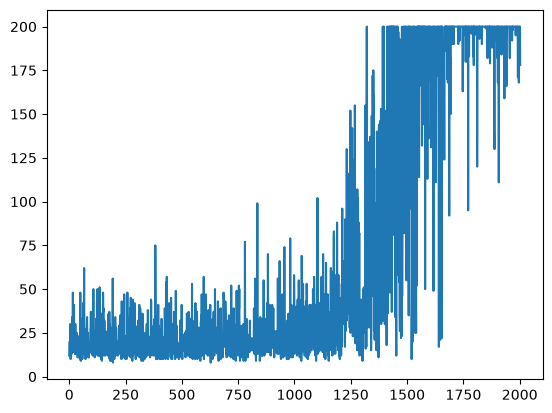

In [72]:
# looking at plot
plt.plot(results_ppo)
plt.show()

In [73]:
#showing video
record_episode(policy_network)
show_video()

Episode reward: 186.0


In [74]:
# watching it live
watch_episode(policy_network, episodes=3)